# NLP in Python: From Your First Token to Big-Data Pipelines
### A hands-on, annotated Titanic notebook · beginner → intermediate → advanced

**What you will build:** a text classifier, visualize its features and mistakes, compare it with standard ML, tune a safe pipeline, and learn when to switch from scikit-learn to incremental learning or Spark.

**Your familiar data loading method:** `pd.read_csv()` from the same public GitHub mirror of Kaggle Titanic training data that you previously used. No API key or KaggleHub required.

> **Crucial limitation:** Titanic has **891 labeled passengers**, not a large text corpus. `Name`, `Ticket`, and `Cabin` are short, partly structured strings—not meaningful reviews, articles, or chats. This notebook teaches the NLP *workflow* using Titanic and uses a few miniature sentences to illustrate language-specific problems. The Spark/transformer sections teach techniques you would transfer to genuinely large text datasets; their performance on Titanic is not evidence of big-data advantage.

**How to use:** Run cells top-to-bottom. Stop after **Part A** for a useful first lesson. All ordinary cells need only pandas, NumPy, matplotlib, and scikit-learn. **Part D** has optional installations; it does not run by default.

## Lesson plan & checkpoints

| Stage | Time* | What you will understand | Deliverable |
|---|---:|---|---|
| **A1. Words → tokens** | 15 min | case, punctuation, stopwords, negation | token examples + plots |
| **A2. Tokens → vectors** | 20 min | bag of words, TF-IDF, n-grams, sparsity | annotated feature heatmaps |
| **A3. First classifier** | 20 min | titles/names/tickets, train/test split, baseline | first reproducible NLP model |
| **B1. Evaluate** | 25 min | confusion matrix, precision, recall, F1, ROC-AUC, PR-AUC | validation plots |
| **B2. Better pipelines** | 25 min | preprocessing + tabular + text, leakage, cross-validation | fair model comparison |
| **C1. Tune** | 20 min | `GridSearchCV`, hyperparameters, test once | final held-out score |
| **C2. Understand failure** | 15 min | suspicious words, family overlaps, data quality | feature inspection |
| **D1. Scale** | 25 min | sparse matrices, hashing, minibatches | streaming-style prototype |
| **D2. Distributed NLP** | optional | Spark `Tokenizer → HashingTF → IDF → LR` | scalable pipeline |
| **D3. Deep NLP** | optional | embeddings / transformers and trade-offs | semantic demo |
| **E. Real-work template** | 15 min | repeatable robust pipeline | compact reusable solution |

*Approximate learning times, not runtime guarantees. **First 30% of the notebook is the essential visual foundation.**

**Mental map:** `raw text → clean/tokenize → numeric vectors → model → evaluate → tune → deploy/scale`.

## Start here: install, then use Run All (through Part C)

In your terminal, in the same `uv` project you have been using:

```bash
uv add pandas numpy matplotlib scikit-learn ipykernel
```

Register/select that virtual environment as your Jupyter kernel. Or use an existing kernel that already has these packages.

**Why the particular metrics?** The target `Survived` is **binary**: 1 = survived, 0 = did not survive. We will use **ROC-AUC** to tune a model's overall ranking, and show **accuracy, precision, recall, F1, and average precision** so an apparently good AUC cannot hide bad predictions. Kaggle's original competition uses **accuracy** for its submission leaderboard, but our learning goal includes understanding mistakes. The threshold for precision/recall/F1 is **0.50** unless we explicitly change it.

# Part A · Understand text, visually

## A0. Import and load the **same Titanic CSV link you used previously**

**Source:** [original Kaggle Titanic competition](https://www.kaggle.com/c/titanic/data); [the public DataScienceDojo GitHub CSV mirror](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv). The mirror includes the 891 labeled training examples and can be passed straight to `pd.read_csv`.

**Why this download method?** It is just a normal CSV file served by GitHub, so it does not require Kaggle authentication. Internet access is required when you run the cell. Do not use Kaggle's unlabeled `test.csv` for evaluation: its actual `Survived` labels are not available there.

In [3]:
import re  # Python's built-in regular-expression functions for text patterns.
import numpy as np  # Numerical arrays and simple calculations.
import pandas as pd  # Load and explore CSV tables.
import matplotlib.pyplot as plt  # Make our learning visual.

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"  # The exact familiar CSV mirror URL.
df = pd.read_csv(url)  # Read the remote CSV into a DataFrame.
print("Rows and columns:", df.shape)  # Expect 891 rows and 12 original columns.
display(df.head(5))  # Look at the first five passengers and column names.

Rows and columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print(df[["Name", "Ticket", "Cabin", "Survived"]].head(7).to_string(index=False))  # See the available short text fields and the label.
print("Missing values:")  # Introduce the missing-data check.
print(df[["Name", "Ticket", "Cabin"]].isna().sum())  # Count missing strings before filling anything.

                                               Name           Ticket Cabin  Survived
                            Braund, Mr. Owen Harris        A/5 21171   NaN         0
Cumings, Mrs. John Bradley (Florence Briggs Thayer)         PC 17599   C85         1
                             Heikkinen, Miss. Laina STON/O2. 3101282   NaN         1
       Futrelle, Mrs. Jacques Heath (Lily May Peel)           113803  C123         1
                           Allen, Mr. William Henry           373450   NaN         0
                                   Moran, Mr. James           330877   NaN         0
                            McCarthy, Mr. Timothy J            17463   E46         0
Missing values:
Name        0
Ticket      0
Cabin     687
dtype: int64


**Notice:** `Name` includes courtesy titles such as `Mr.` or `Mrs.`; `Ticket` contains codes and numbers; `Cabin` is often missing. This is **text processing** but barely *natural language understanding*. Later, a model may learn social and ticket patterns, not the *meaning of sentences*.

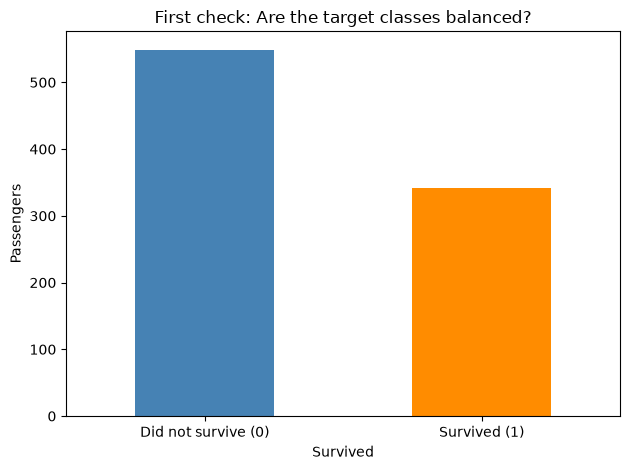

In [20]:
counts = df["Survived"].value_counts()  # Count examples of each true class (0 and 1).
ax = counts.plot(kind="bar", color=["steelblue", "darkorange"],rot=0)  # Visualize class balance, one bar per outcome.
ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])  # Replace number codes with plain-English labels.
ax.set_ylabel("Passengers")  # Bar height shows how many passengers are in each class.
ax.set_title("First check: Are the target classes balanced?")  # State the purpose of the chart.
plt.tight_layout()  # Prevent labels from being cropped.
plt.show()  # Render the plot in the notebook.

In [8]:
counts

Survived
0    549
1    342
Name: count, dtype: int64

## A1. Text → tokens (pieces of text)

- A **document** is one text input (a passenger name, message, review, or article).
- A **token** is a unit such as a word or punctuation mark.
- **Tokenization** is turning text into those units.
- **Normalization** is making consistent representations, often lowercasing; not the same as scaling numeric features.

**Simple string methods first**; then use a regular expression (*regex*) to treat punctuation as separators.

In [22]:
example = df.loc[0, "Name"]  # Choose the first real passenger's name as our tiny document.
print("Original:", example)  # See punctuation and capitalization.
print("Lowercase:", example.lower())  # Convert capitals to lowercase so 'Mr' and 'mr' match.
print("Split:", example.lower().split())  # Split at spaces only; punctuation like 'mr.' remains.
tokens = re.findall(r"[a-z]+", example.lower())  # Pull out letter-only word chunks, dropping commas and periods.
print("Regex tokens:", tokens)  # Check how the tokenization changed the name.

Original: Braund, Mr. Owen Harris
Lowercase: braund, mr. owen harris
Split: ['braund,', 'mr.', 'owen', 'harris']
Regex tokens: ['braund', 'mr', 'owen', 'harris']


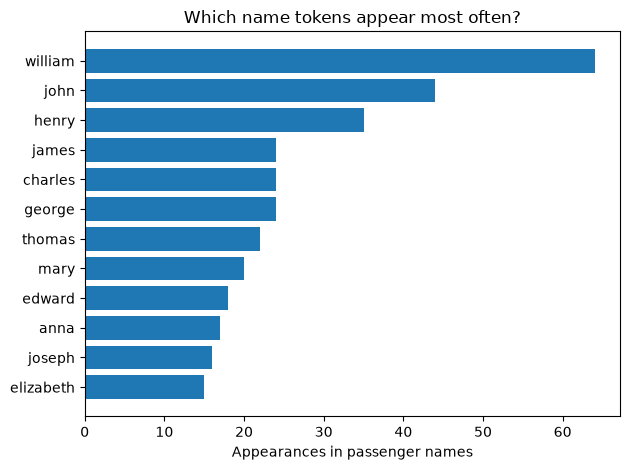

In [26]:
from collections import Counter  # Count how often items occur in a list.
words = re.findall(r"[a-z]+", " ".join(df["Name"].fillna("")).lower())  # Tokenize all names as a quick exploratory demo.
words = [word for word in words if word not in ["mr", "mrs", "miss", "master"]]
common = Counter(words).most_common(12)  # Keep the 12 most frequent tokens to avoid a crowded plot.
labels = [word for word, count in common]  # Extract x-axis labels from the (word, count) pairs.
values = [count for word, count in common]  # Extract y-axis counts from those same pairs.
plt.barh(labels[::-1], values[::-1])  # Draw most common words; reverse order for easier reading.
plt.xlabel("Appearances in passenger names")  # Define the count unit.
plt.title("Which name tokens appear most often?")  # Explain what pattern to look for.
plt.tight_layout()  # Fit axis labels.
plt.show()  # Display the bar chart.

### Stopwords, stemming, lemmatization, and negation

| Technique | Meaning | Example | Important warning |
|---|---|---|---|
| **Stopword removal** | Delete frequent function words | `the`, `is`, `and` | `not` can reverse meaning; don't drop it blindly |
| **Stemming** | Mechanically shorten word forms | `running` → `run` or `runn` | May produce non-words |
| **Lemmatization** | Map word to dictionary form, often using grammar | `better` → `good` (context-dependent) | Needs language-aware tooling |
| **N-grams** | Use sequences of **n** neighboring tokens | `not good` is a bigram (`n=2`) | More context, many more features |

With Titanic **names**, aggressively removing short words may eliminate precisely the courtesy-title information we need.

In [29]:
examples = ["The passenger > survived", "The passenger did not survive"]  # Miniature language examples; NOT Titanic training labels.
for sentence in examples:  # Check each sentence in the toy list.
    print(re.findall(r"[a-z]+", sentence.lower()))  # Keep 'not': its presence changes the sentence's meaning.

['the', 'passenger', 'survi', 'ved']
['the', 'passenger', 'did', 'not', 'survive']


### Tiny code demonstration: why automatic stopword deletion can be dangerous

Some built-in English stopword lists include **`not`**. See what happens if we throw out all those common words. It is usually better to **test whether stopword removal improves cross-validation results**, rather than apply it by default.

In [30]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS  # scikit-learn's built-in English list of common words.
negation_words = ["the", "passenger", "did", "not", "survive"]  # Tokenized illustrative sentence.
filtered = [word for word in negation_words if word not in ENGLISH_STOP_WORDS]  # Remove every word found in that stopword set.
print("Before:", negation_words)  # See the full meaning-bearing original list.
print("After:", filtered)  # Notice that dropping 'not' can reverse or obscure the intended meaning.
print("Is 'not' a built-in stopword?", "not" in ENGLISH_STOP_WORDS)  # Confirm this particular implementation's stopword choice.

Before: ['the', 'passenger', 'did', 'not', 'survive']
After: ['passenger', 'did', 'survive']
Is 'not' a built-in stopword? True


## A2. Bag of words: the first numerical text model

**Bag of words (BoW):** build a vocabulary and count each token in each document. The vector cares about **which words appear**, not their order. A row is one document; a column is a word; a cell is a count.

**Parameters:** `CountVectorizer(lowercase=True)` is the default, and `token_pattern=r'(?u)\b\w\w+\b'` usually ignores 1-character tokens. Alternatives: `binary=True` for presence/absence; `stop_words='english'` (caution with negation); `min_df=2` to drop rare words; `max_features=1000` to cap vocabulary size. We'll use defaults so you can see the raw result.

In [8]:
from sklearn.feature_extraction.text import CountVectorizer  # Turn text into word-count feature matrices.
sentences = ["passenger survived", "passenger did not survive", "survive the voyage"]  # Tiny illustration corpus.
bow = CountVectorizer()  # Create a word-count vectorizer with default tokenization.
bow_numbers = bow.fit_transform(sentences)  # Learn vocabulary and count occurrences (fit + transform).
word_table = pd.DataFrame(bow_numbers.toarray(), columns=bow.get_feature_names_out())  # Convert a TINY sparse result to a display table.
display(word_table)  # Each row is a sentence; each column is a word count.

,did,not,passenger,survive,survived,the,voyage
0,0,0,1,0,1,0,0
1,1,1,1,1,0,0,0
2,0,0,0,1,0,1,1


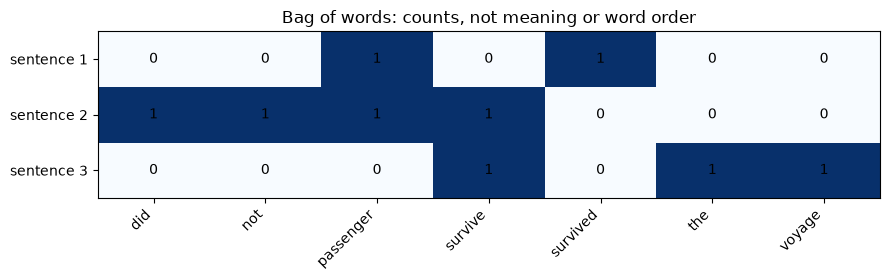

In [9]:
fig, ax = plt.subplots(figsize=(9, 2.9))  # Make a compact heatmap canvas.
heat = ax.imshow(word_table.to_numpy(), cmap="Blues", aspect="auto")  # Shade cells according to word counts.
ax.set_xticks(range(len(word_table.columns)), labels=word_table.columns, rotation=45, ha="right")  # Show each token on x-axis.
ax.set_yticks(range(len(sentences)), labels=["sentence 1", "sentence 2", "sentence 3"])  # Label each input text row.
for r in range(word_table.shape[0]):  # Visit each document row to annotate its cells.
    for c in range(word_table.shape[1]):  # Visit each vocabulary column in that row.
        ax.text(c, r, str(word_table.iat[r, c]), ha="center", va="center")  # Write the exact count inside that square.
ax.set_title("Bag of words: counts, not meaning or word order")  # Highlight what BoW does and misses.
plt.tight_layout()  # Keep labels visible.
plt.show()  # Display the annotated heatmap.

### Why BoW sometimes fails: *not good* versus *good*

If two sentences have nearly the same words but a different order, unigrams (single-word features) can fail. **Bigrams** (`ngram_range=(1,2)`) add adjacent two-word phrases; they capture `not good` but still do not truly *understand* complex negation, sarcasm, long-range context, or polysemy (*bank* = financial institution vs riverbank).

In [10]:
negation_examples = ["good not bad", "not good bad"]  # Same words in different order, so their unigram counts match.
unigrams = CountVectorizer(ngram_range=(1, 1))  # Use only individual words: standard bag of words.
bigrams = CountVectorizer(ngram_range=(1, 2))  # Use both individual words and adjacent word pairs.
print("Same unigram vectors:", (unigrams.fit_transform(negation_examples).toarray()[0] == unigrams.transform(negation_examples).toarray()[1]).all())  # Confirm identical one-word counts.
print("Unigram + bigram feature names:", bigrams.fit(negation_examples).get_feature_names_out())  # Notice 'good not' and 'not good' are distinct.

Same unigram vectors: True
Unigram + bigram feature names: ['bad' 'good' 'good bad' 'good not' 'not' 'not bad' 'not good']


### Visualize how n-grams increase feature count

`ngram_range=(1,1)` captures single words; `(1,2)` captures words **and** adjacent pairs; `(1,3)` also captures three-word sequences. These larger vocabularies may help context but require more memory and can overfit tiny datasets.

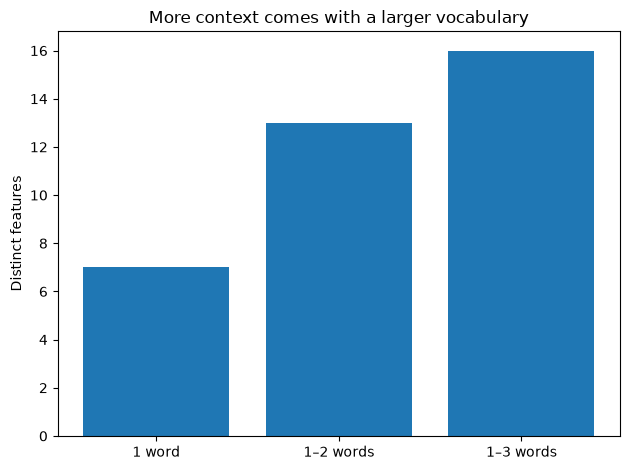

In [11]:
ngram_options = [(1, 1), (1, 2), (1, 3)]  # Compare three maximum context windows.
feature_counts = [len(CountVectorizer(ngram_range=option).fit(sentences).get_feature_names_out()) for option in ngram_options]  # Fit vocabulary on our three sample sentences for each setting.
plt.bar(["1 word", "1–2 words", "1–3 words"], feature_counts)  # Show how longer word sequences expand dimensionality.
plt.ylabel("Distinct features")  # Feature count, not document count or model accuracy.
plt.title("More context comes with a larger vocabulary")  # Interpret the plot's main tradeoff.
plt.tight_layout()  # Prevent labels from clipping.
plt.show()  # Display the n-gram comparison.

## A3. TF-IDF: count words, then downweight common words

**TF-IDF** = *term frequency × inverse document frequency*. A term's importance rises when it appears in a document but is comparatively uncommon across documents. By default scikit-learn also applies L2 normalization (rescales each vector to length 1).

**Why use it?** For a linear classifier, TF-IDF is a strong fast baseline, often better than raw count magnitudes. **Alternatives:** counts (`CountVectorizer`), binary flags, character n-grams, or neural embeddings. **Parameters to know:** `ngram_range`, `min_df`, `max_df`, `max_features`, `sublinear_tf`, `norm`.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer  # Import weighted word-vector creation.
tfidf = TfidfVectorizer()  # Use simple defaults: unigrams, inverse document frequency, L2 norm.
weighted = tfidf.fit_transform(sentences)  # Learn vocabulary/IDF and make a sparse numeric matrix.
tfidf_table = pd.DataFrame(weighted.toarray().round(2), columns=tfidf.get_feature_names_out())  # Inspect only our three tiny demo sentences.
display(tfidf_table)  # Compare decimals with the integer BoW counts above.

,did,not,passenger,survive,survived,the,voyage
0,0.00,0.00,0.61,0.00,0.8,0.00,0.00
1,0.56,0.56,0.43,0.43,0.0,0.00,0.00
2,0.00,0.00,0.00,0.47,0.0,0.62,0.62


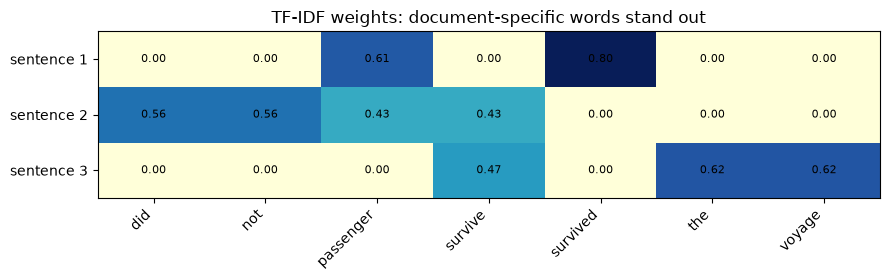

In [13]:
fig, ax = plt.subplots(figsize=(9, 2.9))  # Make a canvas the same size as the BoW chart.
ax.imshow(tfidf_table.to_numpy(), cmap="YlGnBu", aspect="auto")  # Color each TF-IDF weight rather than raw count.
ax.set_xticks(range(len(tfidf_table.columns)), labels=tfidf_table.columns, rotation=45, ha="right")  # Label weighted vocabulary columns.
ax.set_yticks(range(len(sentences)), labels=["sentence 1", "sentence 2", "sentence 3"])  # Label source sentences.
for r in range(tfidf_table.shape[0]):  # Iterate over displayed text rows.
    for c in range(tfidf_table.shape[1]):  # Iterate over vocabulary columns.
        ax.text(c, r, f"{tfidf_table.iat[r, c]:.2f}", ha="center", va="center", fontsize=8)  # Annotate each numeric weight.
ax.set_title("TF-IDF weights: document-specific words stand out")  # Compare this with the bag-of-words plot.
plt.tight_layout()  # Prevent text clipping.
plt.show()  # Render the chart.

### Quick checkpoint before moving on

Try explaining each in one sentence: **token**, **vocabulary**, **bag of words**, **TF-IDF**, **bigram**, **sparse matrix**. A *sparse matrix* stores mostly non-zero entries efficiently, instead of storing millions of zeros explicitly.

**Experiment:** change `TfidfVectorizer()` to `TfidfVectorizer(ngram_range=(1, 2))`, rerun its cell, and compare the feature count. Then switch back before continuing.

## A4. Build a text field from actual Titanic data

For NLP we need one text column. Use `Name` and `Ticket` only; both exist for the passengers. Separately, `Pclass`, `Sex`, `Age`, etc. remain structured non-NLP features. **No outcome words** such as `survived` go into the feature text. `Cabin` is omitted here because so many values are missing; we could later model its missingness separately.

The ticket codes and surnames may act like **identifiers**; they are not evidence that a model understands language. We will test their actual predictive value against structured ML.

In [14]:
df["PassengerText"] = df["Name"].fillna("") + " ticket " + df["Ticket"].fillna("")  # Concatenate two available input strings without adding the answer.
print(df["PassengerText"].head(3).to_string(index=False))  # Verify that names and ticket codes, not outcomes, appear.

          Braund, Mr. Owen Harris ticket A/5 21171
Cumings, Mrs. John Bradley (Florence Briggs Tha...
    Heikkinen, Miss. Laina ticket STON/O2. 3101282


Name
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Rev         6
Major       2
Mlle        2
Col         2
Don         1
Mme         1
Ms          1
Name: count, dtype: int64


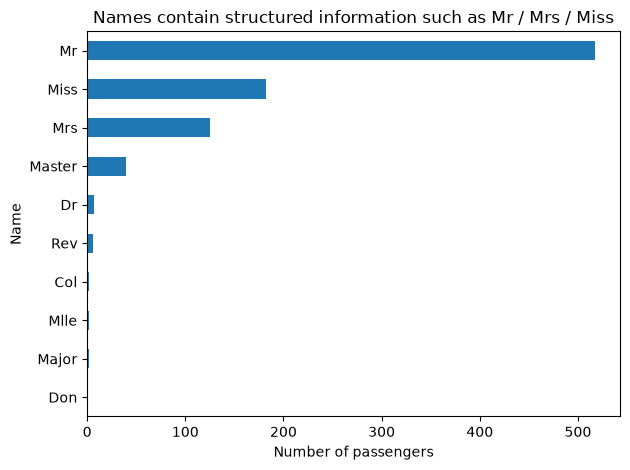

In [15]:
titles = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False).fillna("unknown")  # Extract name titles between a comma and period.
print(titles.value_counts().head(12))  # Count the common courtesy titles.
titles.value_counts().head(10).sort_values().plot(kind="barh")  # Visualize dominant title categories.
plt.xlabel("Number of passengers")  # Explain bar length.
plt.title("Names contain structured information such as Mr / Mrs / Miss")  # Clarify what NLP might learn.
plt.tight_layout()  # Keep all labels visible.
plt.show()  # Display the title plot.

## A5. Define X (features) and y (target); reserve the holdout now

- **X:** input columns known *before* the event; no `Survived` and no passenger ID.
- **y:** `Survived`, with 1 as the positive class.
- **80/20 split:** roughly 80% for development and cross-validation; 20% untouched until our final report.
- `stratify=y` approximately preserves the survival rate in both parts.
- `random_state=42` makes the same random split reproducible; 42 is arbitrary, not magically optimal.

**Alternatives:** group-wise splits by family/ticket or time-based splits are more realistic for certain applications. Random splitting can let relatives appear in both parts, so treat this as a *teaching split*, not a deployment audit.

In [16]:
from sklearn.model_selection import train_test_split  # Split development data from the final holdout set.
feature_cols = ["PassengerText", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch", "Embarked"]  # Input fields available at prediction time.
X = df[feature_cols]  # Select only feature columns, excluding the answer.
y = df["Survived"]  # Set the target to the known binary survival outcome.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)  # Reserve 20% and preserve class ratios.
print("Development rows:", len(X_train), "Final test rows:", len(X_test))  # Confirm both groups have data.

Development rows: 712 Final test rows: 179


# Part B · Build, visualize, and evaluate a first NLP model

## B1. Learn the metrics before chasing high scores

A **positive prediction** = predicting survival (1). The **decision threshold** below is 0.50: a predicted probability at least 50% is called class 1.

| Metric | Intuition / formula | When useful | Caveat |
|---|---|---|---|
| **Accuracy** | `(TP + TN) / all rows` | Balanced classes; Kaggle Titanic official scoring | Can reward predicting the majority class |
| **Precision** | `TP / (TP + FP)` | False positive predictions are costly | May be high if predicting very few positives |
| **Recall / sensitivity** | `TP / (TP + FN)` | Missing a true positive is costly | Predicting all positives gets recall 1.0 |
| **F1** | `2 × precision × recall / (precision + recall)` | Balance precision and recall | Ignores true negatives |
| **Balanced accuracy** | Average recall across both classes | Imbalanced targets | Doesn't use probability confidence |
| **ROC-AUC** | Rank a random positive above a negative | General ranking quality across thresholds | Can be optimistic on very rare positive classes |
| **Average precision (AP)** | Area-like summary of precision-recall staircase | Rare positives; ranking with focus on positive class | Depends on class prevalence; not exactly trapezoidal PR-AUC |
| **Log loss** | Penalty for incorrect probability forecasts | If calibrated probabilities matter | Extreme confident errors heavily penalized |
| **Brier score** | Mean squared error of predicted positive probabilities | Probability calibration | Not comparable to AUC directly |
| **Matthews corr. (MCC)** | Balanced correlation of actual and predicted labels | Severe imbalance | Less intuitive than F1 |

**TP** = survived and predicted survive; **FP** = did not survive but predicted survive; **FN** = survived but predicted not; **TN** = did not survive and predicted not.

**Choice here:** optimize **ROC-AUC** during tuning because we haven't specified the business cost of FP versus FN. Also inspect **average precision, accuracy, precision, recall, and F1**; no single metric settles every use case. Kaggle's metric is **accuracy**.

## B2. First text-only pipeline: `TF-IDF → Logistic Regression`

A **pipeline** fits the text vocabulary on the *training portion of each fold only*, then transforms its validation portion; this prevents leakage from future validation rows into IDF weights.

Why **logistic regression**? Despite the name, it is a fast linear classification model, works well with sparse text features, and its coefficients are easy to inspect. Alternatives: `MultinomialNB` (Naive Bayes, especially with nonnegative count/TF-IDF features), linear SVM, tree models, or a neural network. A word's weight is an association, **not** a causal explanation.

**Parameters:** `max_iter=1000` raises the solver's iteration budget to reduce convergence warnings; `C=1.0` (default) controls inverse regularization strength. **Smaller C = simpler/stronger regularization.**

In [17]:
from sklearn.pipeline import make_pipeline  # Chain steps so they refit safely together during validation.
from sklearn.linear_model import LogisticRegression  # Fast linear classifier suited to sparse text.
from sklearn.model_selection import StratifiedKFold, cross_val_predict  # Create stratified folds and out-of-fold predictions.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # Use 5 balanced folds; shuffle rows once reproducibly.
text_model = make_pipeline(TfidfVectorizer(min_df=2, ngram_range=(1, 2)), LogisticRegression(max_iter=1000))  # Drop singletons; use words + bigrams; fit logistic regression.
oof_prob = cross_val_predict(text_model, X_train["PassengerText"], y_train, cv=cv, method="predict_proba")[:, 1]  # Predict each training row using a model that did NOT train on it.
oof_pred = (oof_prob >= 0.50).astype(int)  # Convert out-of-fold probabilities to class labels with a 50% threshold.
print("OOF rows evaluated:", len(oof_pred))  # Confirm one out-of-fold prediction per development row.

OOF rows evaluated: 712


`OOF` means **out-of-fold**: each row gets its prediction from a model fitted on other rows. This gives useful validation plots *without touching the final test set*. **Cross-validation does not change hyperparameters on its own.** Each fold uses the same hyperparameters; `GridSearchCV` later compares combinations.

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score  # Metrics for yes/no predictions at a threshold.
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, average_precision_score  # Balanced classification and probability ranking metrics.
score_rows = {"accuracy": accuracy_score(y_train, oof_pred), "precision": precision_score(y_train, oof_pred), "recall": recall_score(y_train, oof_pred), "f1": f1_score(y_train, oof_pred), "balanced_accuracy": balanced_accuracy_score(y_train, oof_pred), "roc_auc": roc_auc_score(y_train, oof_prob), "average_precision": average_precision_score(y_train, oof_prob)}  # Compute every metric from predictions or probabilities, as appropriate.
display(pd.Series(score_rows, name="Out-of-fold text NLP").round(3).to_frame())  # Display a compact named metric table.

,Out-of-fold text NLP
accuracy,0.820
precision,0.796
recall,0.714
f1,0.753
balanced_accuracy,0.800
roc_auc,0.825
average_precision,0.727


### B3. Confusion matrix: *what kinds* of mistakes?

Rows represent **true class**; columns represent **predicted class**. You can choose a different 0.50 threshold later: a lower threshold tends to increase recall and false positives; a higher threshold tends to increase precision and false negatives. This is a **trade-off**, not tuning a different model.

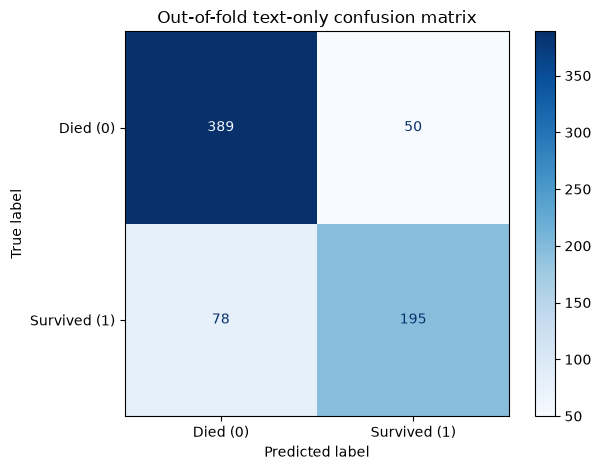

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay  # Plot true vs predicted class counts.
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["Died (0)", "Survived (1)"], cmap="Blues", values_format="d")  # Use OOF class predictions, not training fit scores.
plt.title("Out-of-fold text-only confusion matrix")  # State evaluation scope.
plt.tight_layout()  # Keep class labels visible.
plt.show()  # Display the confusion matrix.

### B4. ROC and precision-recall curves: visualize every threshold

- **ROC curve:** plots **true positive rate** (recall) against **false positive rate**; chance ranking is near AUC = 0.5.
- **Precision-recall curve:** plots precision vs recall; especially revealing when positive class is rare.
- These use **probabilities**, not only 0/1 decisions.
- **AUC** means *area under the curve*. **Average precision** is computed differently from generic trapezoidal PR-area; do not treat them as identical.

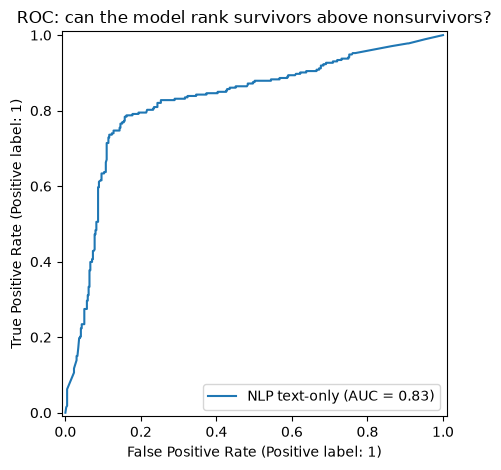

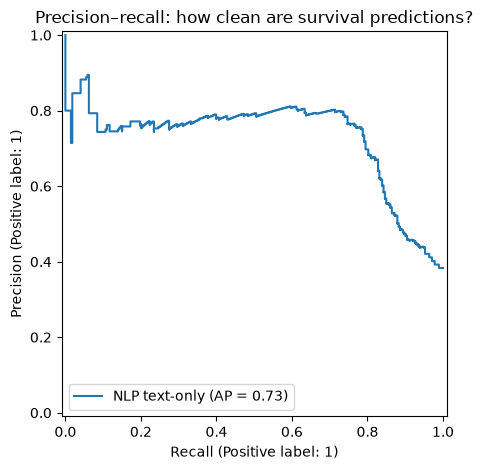

In [20]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay  # Standard validated classification curve plotting tools.
RocCurveDisplay.from_predictions(y_train, oof_prob, name="NLP text-only")  # Show true-positive vs false-positive rate across thresholds.
plt.title("ROC: can the model rank survivors above nonsurvivors?")  # Clarify the ranking question.
plt.tight_layout()  # Fit figure elements.
plt.show()  # Draw the ROC curve.
PrecisionRecallDisplay.from_predictions(y_train, oof_prob, name="NLP text-only")  # Show precision/recall tradeoffs across thresholds.
plt.title("Precision–recall: how clean are survival predictions?")  # Clarify what the second curve adds.
plt.tight_layout()  # Fit elements.
plt.show()  # Draw the precision-recall curve.

### B4a. One model, different probability thresholds

**Threshold choice is not hyperparameter tuning.** The same OOF probabilities can produce different decisions. Use this diagram to see why chasing recall can reduce precision (and vice versa); note that the trade-off may not change monotonically on a small sample.

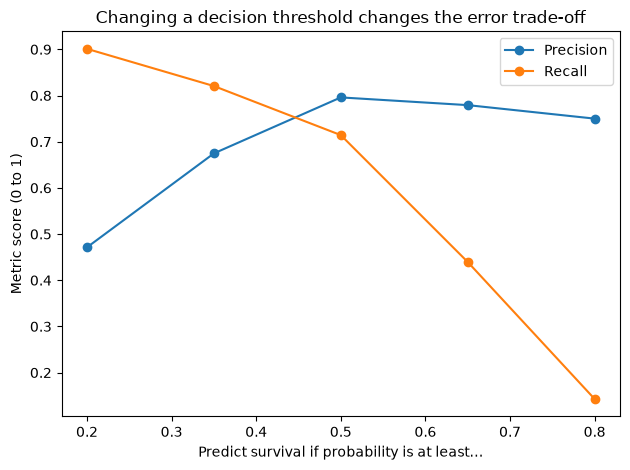

In [21]:
thresholds = [0.20, 0.35, 0.50, 0.65, 0.80]  # Test five explicit survival-probability cutoffs.
precision_at = [precision_score(y_train, (oof_prob >= t).astype(int), zero_division=0) for t in thresholds]  # Compute positive-class precision for each cutoff.
recall_at = [recall_score(y_train, (oof_prob >= t).astype(int), zero_division=0) for t in thresholds]  # Compute positive-class recall for each cutoff.
plt.plot(thresholds, precision_at, marker="o", label="Precision")  # Graph how false positives affect precision.
plt.plot(thresholds, recall_at, marker="o", label="Recall")  # Graph how missed survivors affect recall.
plt.xlabel("Predict survival if probability is at least…")  # Threshold on the x-axis.
plt.ylabel("Metric score (0 to 1)")  # Both plotted metrics are bounded between zero and one.
plt.title("Changing a decision threshold changes the error trade-off")  # Highlight the relationship.
plt.legend()  # Distinguish the two lines.
plt.tight_layout()  # Keep the axis annotations visible.
plt.show()  # Display the threshold comparison.

### B5. What text tokens did the linear classifier learn?

Fit on **development data only**, then inspect coefficients. A positive coefficient is associated with survival (class 1) *in this model*, and a negative coefficient with class 0, after accounting for other tokens. Coefficients can be unstable when words are correlated, rare, or act as family identifiers. **Do not claim they caused survival.**

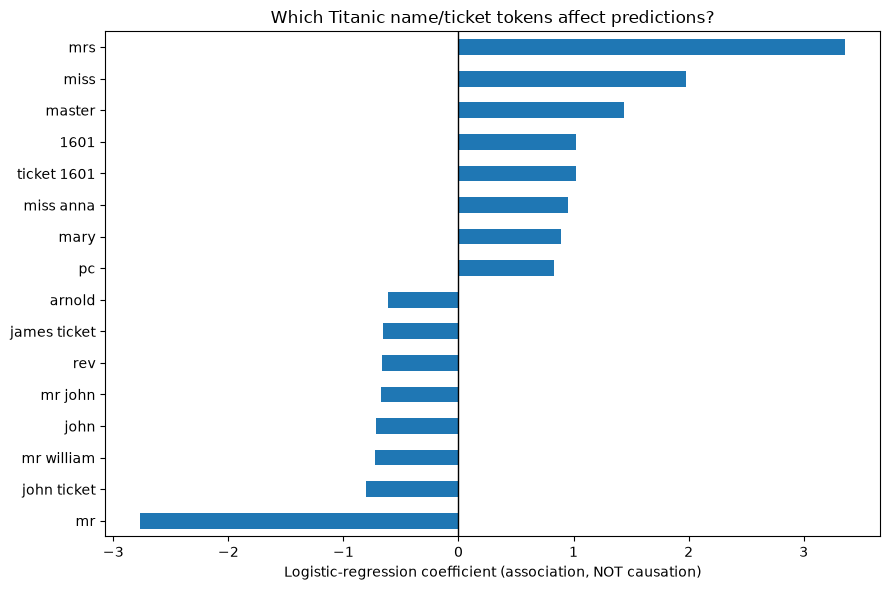

In [22]:
text_model.fit(X_train["PassengerText"], y_train)  # Fit the text pipeline on all available development rows only.
terms = text_model.named_steps["tfidfvectorizer"].get_feature_names_out()  # Recover fitted word/bigram feature names.
weights = text_model.named_steps["logisticregression"].coef_[0]  # Read their learned weights for class 1.
weight_table = pd.Series(weights, index=terms).sort_values()  # Pair each word with a coefficient and sort it.
shown = pd.concat([weight_table.head(8), weight_table.tail(8)])  # Keep 8 most negative and 8 most positive words.
shown.plot(kind="barh", figsize=(9, 6))  # Plot the strongest learned text associations.
plt.axvline(0, color="black", linewidth=1)  # Add the boundary between negative and positive coefficients.
plt.xlabel("Logistic-regression coefficient (association, NOT causation)")  # Explain the x-axis correctly.
plt.title("Which Titanic name/ticket tokens affect predictions?")  # Emphasize dataset-specific nature of results.
plt.tight_layout()  # Make long feature names fit.
plt.show()  # Display the coefficient chart.

## B6. Challenge your NLP model: would simple structured ML be better?

A model that extracts `Mr` or `Mrs` from names may be indirectly relearning **sex and social structure**. Test whether text adds anything beyond familiar structured features. Use **identical cross-validation folds** on the same development rows for a fairer comparison.

**Preprocessing:** numeric missing `Age` with median **inside** CV folds (rather than calculating it on the full dataset); categorical missing `Embarked` with most-frequent **inside** folds; scale numeric data; one-hot encode categories (make numeric indicator columns). **Alternatives:** explicit missingness indicators, more robust imputers, ordinal encoders when appropriate, or models with native missing-value handling. Imputation can distort data; these are transparent baseline choices, not universal rules.

In [23]:
from sklearn.compose import ColumnTransformer  # Apply different transformations to different named input columns.
from sklearn.impute import SimpleImputer  # Learn missing-value replacements from training rows only.
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # Encode categorical labels and standardize numerical scales.
from sklearn.dummy import DummyClassifier  # Majority-class prediction baseline for context.

numeric_cols = ["Pclass", "Age", "Fare", "SibSp", "Parch"]  # Numeric inputs to impute and scale.
categorical_cols = ["Sex", "Embarked"]  # Non-numeric categories to fill/one-hot encode.
num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())  # Median-fill numeric gaps, then zero-center/scale.
cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))  # Fill category gaps and avoid crashing on unseen categories.
structured_prep = ColumnTransformer([("num", num_pipe, numeric_cols), ("cat", cat_pipe, categorical_cols)])  # Apply numeric/categorical preprocessing to the correct columns.
structured_model = make_pipeline(structured_prep, LogisticRegression(max_iter=1000))  # Predict using only structured features.

### Combine numeric, category, and text in one pipeline

This is the **real-world pattern** for mixed datasets. The `ColumnTransformer` sends text through TF-IDF, numbers through imputation/scaling, and categories through one-hot encoding; the resulting features go to one classifier. **Why not pre-fit TF-IDF before CV?** That would allow validation words into training vocabulary/IDF and cause data leakage.

In [24]:
combined_prep = ColumnTransformer([("text", TfidfVectorizer(min_df=2, ngram_range=(1, 2)), "PassengerText"), ("num", num_pipe, numeric_cols), ("cat", cat_pipe, categorical_cols)])  # Define separate transformations for one text column and tabular columns.
combined_model = make_pipeline(combined_prep, LogisticRegression(max_iter=1000))  # Connect all transformed features to a linear classifier.
text_only_on_table = make_pipeline(ColumnTransformer([("text", TfidfVectorizer(min_df=2, ngram_range=(1, 2)), "PassengerText")]), LogisticRegression(max_iter=1000))  # Wrap text-only model so it accepts the same whole X table.

### Optional pipeline diagram

scikit-learn can display the **preprocessing branches** and classifier as a diagram in Jupyter. It is a view of the code you wrote, not another model.

In [25]:
from sklearn import set_config  # Set scikit-learn's notebook representation preference.
set_config(display="diagram")  # Ask Jupyter to show pipelines and column transformers as expandable diagrams.
display(combined_model)  # Visualize the still-unfitted text, numerical, categorical, and classifier stages.

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: 

## B7. Cross-validate four approaches—using the **same folds**

- **Dummy:** predicts the majority class; this sets a minimum sanity check.
- **Text:** TF-IDF on names/tickets only.
- **Structured:** traditional Titanic ML using numeric/categorical fields.
- **Combined:** NLP + traditional ML.

We compare **accuracy** (official Kaggle metric), **ROC-AUC** (ranking; our tune objective), **F1** (thresholded precision/recall balance), and **average precision** (positive-class ranking). Additional metrics are in the table above. **5 folds** provides a reasonable illustration for 712 development rows; 3 folds is faster, 10 folds costs more computation, group CV is better for correlated household identifiers.

In [26]:
from sklearn.model_selection import cross_validate  # Evaluate several metrics over the same CV splits.
models = {"Dummy baseline": DummyClassifier(strategy="most_frequent"), "NLP text": text_only_on_table, "Structured ML": structured_model, "Combined NLP + ML": combined_model}  # Register the four pipelines/models to compare.
scoring = {"Accuracy": "accuracy", "ROC-AUC": "roc_auc", "F1": "f1", "Avg precision": "average_precision"}  # Define evaluation metrics once for all four models.
compare = {}  # Create a place to store the mean cross-validation scores.
for name, model in models.items():  # Evaluate one candidate at a time on identical folds.
    fold_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)  # Refit the entire preprocessing+model on each training fold.
    compare[name] = {metric: fold_scores["test_" + metric].mean() for metric in scoring}  # Average validation metric across the 5 folds.
score_table = pd.DataFrame(compare).T.round(3)  # Assemble comparisons into a convenient rows=approaches table.
display(score_table)  # Compare NLP and non-NLP without using the held-out test data.

,Accuracy,ROC-AUC,F1,Avg precision
Dummy baseline,0.617,0.500,0.000,0.383
NLP text,0.820,0.826,0.753,0.733
Structured ML,0.796,0.855,0.726,0.837
Combined NLP + ML,0.823,0.876,0.764,0.852


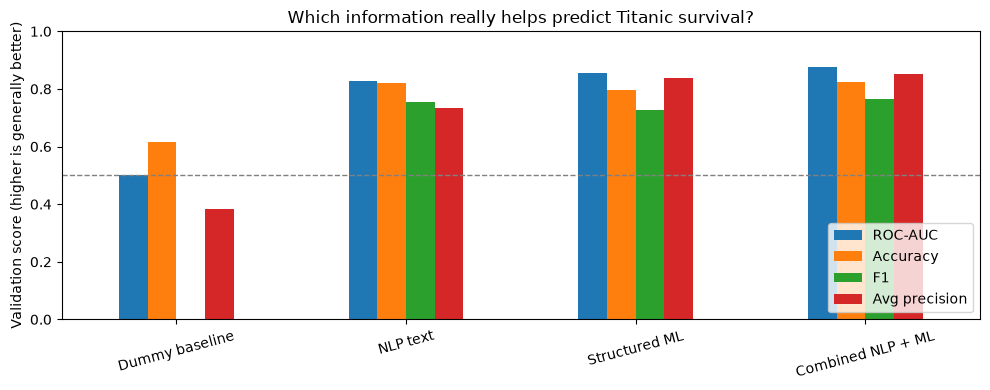

In [27]:
score_table[["ROC-AUC", "Accuracy", "F1", "Avg precision"]].plot(kind="bar", figsize=(10, 4), rot=15, ylim=(0, 1))  # Compare all four metrics for all four models.
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)  # Draw a reference at 0.5; this is CHANCE only for ROC-AUC, not for other metrics.
plt.ylabel("Validation score (higher is generally better)")  # Explain score direction, while remembering different baselines.
plt.title("Which information really helps predict Titanic survival?")  # Put the scientific question over the chart.
plt.legend(loc="lower right")  # Identify each metric's bar color.
plt.tight_layout()  # Avoid clipping chart labels.
plt.show()  # Render the comparison.

**Interpretation:** If `Structured ML` beats `NLP text`, that is normal: Titanic is overwhelmingly a tabular problem. If `Combined` improves only slightly or not at all, extra text features may be noise. **Do not select a winner based on a held-out test score.** The next section tunes on development folds only.

# Part C · Tune safely, inspect errors, test once

## C1. Grid search: *now* cross-validation varies hyperparameters

`GridSearchCV` tests each combination of parameters, performs cross-validation for each, selects the best **mean validation ROC-AUC**, and **refits** it on the full development set.

| Parameter | Here | Why | Alternatives |
|---|---|---|---|
| `text__ngram_range` | `(1,1)` vs `(1,2)` | Words alone vs words+bigrams | `(2,2)`, character n-grams |
| `text__min_df` | 2 vs 4 | Remove extremely rare tokens/ID-like noise | 1 (keeps everything), 3, `0.01` (fraction) |
| `logisticregression__C` | 0.3, 1, 3 | Tune regularization | 0.01, 0.1, 10; logarithmic search |
| `cv` | 5 stratified folds | Repeated validation on development rows | 3/10 folds, grouped CV |
| `scoring` | `roc_auc` | Compare probability ranking without choosing a threshold | `average_precision`, `f1`, `neg_log_loss`, `accuracy` |

**Cost:** `2 × 2 × 3 = 12` combinations and `12 × 5 = 60` fold fits, plus one final refit. This is small enough for a laptop with 891 rows. For very large grids use `RandomizedSearchCV`, Optuna (extra package), or Bayesian optimization.

In [28]:
from sklearn.model_selection import GridSearchCV  # Cross-validate alternative parameter combinations.
param_grid = {"columntransformer__text__ngram_range": [(1, 1), (1, 2)], "columntransformer__text__min_df": [2, 4], "logisticregression__C": [0.3, 1.0, 3.0]}  # Try 12 explicit model configurations.
search = GridSearchCV(combined_model, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)  # Optimize development-fold ROC-AUC and refit best pipeline.
search.fit(X_train, y_train)  # Fit ONLY on development data; held-out test stays untouched.
print("Best parameters:", search.best_params_)  # Show which vocabulary settings and regularization won.
print("Mean CV ROC-AUC:", round(search.best_score_, 3))  # Summarize selected config's validation score.

Best parameters: {'columntransformer__text__min_df': 4, 'columntransformer__text__ngram_range': (1, 1), 'logisticregression__C': 1.0}
Mean CV ROC-AUC: 0.878


In [29]:
search_table = pd.DataFrame(search.cv_results_)  # Convert every candidate's cross-validation details to a table.
cols = ["param_columntransformer__text__ngram_range", "param_columntransformer__text__min_df", "param_logisticregression__C", "mean_test_score", "std_test_score", "rank_test_score"]  # Select only the interpretable tuning columns.
display(search_table[cols].sort_values("rank_test_score").head(12))  # Inspect average fold ROC-AUC and its variability.

,param_columntransformer__text__ngram_range,param_columntransformer__text__min_df,param_logisticregression__C,mean_test_score,std_test_score,rank_test_score
7,"(1, 1)",4,1.0,0.877918,0.021651,1
1,"(1, 1)",2,1.0,0.876612,0.022834,2
6,"(1, 1)",4,0.3,0.875967,0.019441,3
4,"(1, 2)",2,1.0,0.875838,0.024136,4
10,"(1, 2)",4,1.0,0.875832,0.021948,5
5,"(1, 2)",2,3.0,0.874782,0.027847,6
9,"(1, 2)",4,0.3,0.874596,0.019574,7
2,"(1, 1)",2,3.0,0.874427,0.028354,8
8,"(1, 1)",4,3.0,0.873610,0.026273,9
0,"(1, 1)",2,0.3,0.870234,0.018604,10


### C2. Final holdout: evaluate **once**, after selection

We now apply the best cross-validated configuration to rows never used for fitting, feature engineering statistics, validation, or tuning. This **single holdout estimate** is less optimistic than training accuracy; because Titanic has only 179 held-out passengers, the score also has sampling uncertainty.

In [30]:
from sklearn.metrics import classification_report, log_loss, brier_score_loss  # Get class-by-class metrics and probability losses.
best_model = search.best_estimator_  # The pipeline refitted on all development rows with the winning settings.
test_prob = best_model.predict_proba(X_test)[:, 1]  # Generate untouched holdout probabilities for survival.
test_pred = (test_prob >= 0.50).astype(int)  # Apply an explicit, interpretable 50% decision threshold.
print(classification_report(y_test, test_pred, target_names=["Died", "Survived"], zero_division=0))  # Show precision, recall, F1, and support for each class.
print("Holdout ROC-AUC:", round(roc_auc_score(y_test, test_prob), 3))  # Evaluate ranking ability on unseen rows.
print("Holdout average precision:", round(average_precision_score(y_test, test_prob), 3))  # Evaluate positive-class precision/recall ranking.
print("Holdout log loss:", round(log_loss(y_test, test_prob), 3))  # Penalize overconfident wrong probabilities (lower is better).
print("Holdout Brier score:", round(brier_score_loss(y_test, test_prob), 3))  # Average squared probability error (lower is better).

              precision    recall  f1-score   support

        Died       0.84      0.89      0.87       110
    Survived       0.81      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179

Holdout ROC-AUC: 0.865
Holdout average precision: 0.801
Holdout log loss: 0.434
Holdout Brier score: 0.133


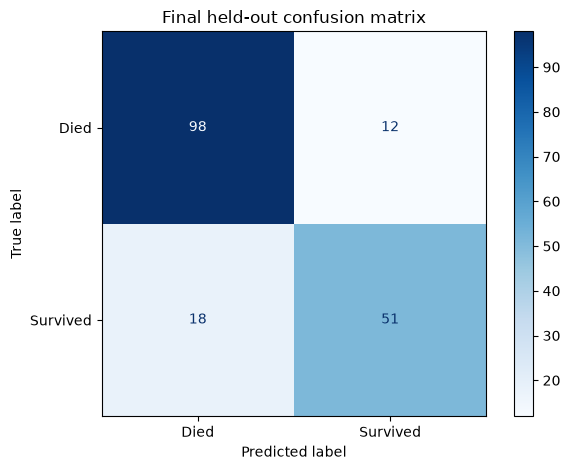

In [31]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Died", "Survived"], cmap="Blues", values_format="d")  # Show mistakes on untouched rows.
plt.title("Final held-out confusion matrix")  # Differentiate this from the earlier OOF plot.
plt.tight_layout()  # Prevent cropped labels.
plt.show()  # Display the final matrix.

### C3. Why NLP on Titanic might mislead you

- **Weak language:** Titles and ticket codes are semi-structured. High survival prediction does not demonstrate semantic NLP.
- **Shared families/tickets:** Random train/test splitting can put related passengers in both sets, creating optimistic evaluation. A `GroupKFold` or group-aware holdout by ticket/family tests a tougher generalization question; groups are imperfect household proxies.
- **Data leakage:** Never put `Survived` into `PassengerText`, fit vocabulary/IDF on all rows before the split, or impute numeric values before CV.
- **Small test group:** Small shifts in who lands in validation can alter scores; inspect fold variation and keep the final holdout for one evaluation.
- **Historical correlations:** Titles/sex/class can be strongly associated with outcomes here, but that doesn't generalize into language understanding or justify causal claims.

**Possible next experiment (do not automatically assume it improves results):** try `analyzer='char'` with `ngram_range=(2,4)` to represent ticket spellings, and compare by cross-validation. Character n-grams can also multiply feature counts and fit identifiers too closely.

### C4. Advanced evaluation: keep shared ticket groups in separate folds

With people from one ticket group showing up in both training and validation, the model can learn ticket identity rather than genuinely generalizing. **StratifiedGroupKFold** is a useful alternative: it tries to keep class proportions reasonable while ensuring each ticket appears in **only one fold's validation group**. This evaluates a harder question.

**Caveats:** Ticket is not a perfect family/household identifier. This checks *development* folds only; the main final test above was still random, so the final number could remain optimistic. A fully group-held-out test would require a fresh split and an entirely separate experimental design.

In [32]:
from sklearn.model_selection import StratifiedGroupKFold  # Combine label balancing with group-exclusive validation folds.
ticket_groups = df.loc[X_train.index, "Ticket"].fillna("missing")  # Retrieve only development passengers' ticket identifiers.
cv_groups = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # Avoid placing the same ticket group in training and validation simultaneously.
group_scores = cross_validate(best_model, X_train, y_train, groups=ticket_groups, cv=cv_groups, scoring={"ROC-AUC": "roc_auc", "Accuracy": "accuracy"})  # Re-evaluate fixed selected settings on group-exclusive folds.
print("Ticket-group CV ROC-AUC:", round(group_scores["test_ROC-AUC"].mean(), 3))  # Show mean harder-validation ranking score.
print("Ticket-group CV accuracy:", round(group_scores["test_Accuracy"].mean(), 3))  # Show mean harder-validation classification score.

Ticket-group CV ROC-AUC: 0.861
Ticket-group CV accuracy: 0.819


# Part D · Bigger data & deeper language (optional)

## D1. Sparse matrices: the main memory-saving trick

Most words don't appear in most documents. Vectorizers use a **sparse matrix** to store nonzero entries efficiently. On true corpora, avoid `.toarray()`; it can exhaust RAM. We only used `.toarray()` for the 3-sentence teaching graphics.

In [33]:
compact_tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2))  # Fit a small realistic vocabulary from development text.
sparse_X = compact_tfidf.fit_transform(X_train["PassengerText"])  # Build a sparse matrix, not a dense 2D table.
possible_cells = sparse_X.shape[0] * sparse_X.shape[1]  # Compute how many entries a dense matrix would store.
nonzero_cells = sparse_X.nnz  # Read how many entries are actually stored as nonzero values.
print("Shape:", sparse_X.shape)  # Show documents by features.
print("Nonzero share:", f"{nonzero_cells / possible_cells:.2%}")  # Quantify sparsity: small is memory friendly.
print("Sparse value bytes:", sparse_X.data.nbytes)  # Count raw nonzero value storage only, excluding index/metadata overhead.

Shape: (712, 797)
Nonzero share: 0.74%
Sparse value bytes: 33400


## D2. Hashing: fixed-memory vocabulary without `.fit()`

`HashingVectorizer` hashes tokens into a fixed number of buckets and **does not need to learn a dictionary**. Good for streaming and changing vocabularies. **Trade-off:** two words may collide in the same bucket, and original feature names are lost. `n_features=2**12` means **4,096 buckets**, chosen small for this notebook; a real corpus often needs `2**18` or more. `alternate_sign=False` yields nonnegative counts/weights and simplifies interpretation, at some statistical trade-off for collisions. **TF-IDF's inverse-document-frequency component generally needs a fitted document corpus; hashing alone does not compute learned IDF.**

In [34]:
from sklearn.feature_extraction.text import HashingVectorizer  # Fixed-dimensional text vectors without a learned vocabulary.
from sklearn.linear_model import SGDClassifier  # Incrementally train a linear model using gradient updates.
hasher = HashingVectorizer(n_features=2**12, alternate_sign=False, ngram_range=(1, 2))  # Produce 4096 hashed unigram/bigram features.
hashed_X = hasher.transform(X_train["PassengerText"])  # Transform immediately; hashing needs no fit.
print("Hashed matrix:", hashed_X.shape, "stored nonzeros:", hashed_X.nnz)  # Check memory-friendly output shape and sparsity.

Hashed matrix: (712, 4096) stored nonzeros: 8089


### D3. Mini-batches with `partial_fit()`

In real streaming systems, data arrives in **batches**. `SGDClassifier.partial_fit` updates an existing classifier instead of retraining from scratch. We replay tiny Titanic batches only to practice the syntax; it does **not** create genuine big data. `loss='log_loss'` gives logistic-style probability estimates; alternatives include `'hinge'` (linear SVM loss) and `'modified_huber'`. Incremental SGD is sensitive to learning rate, order, scaling, and class imbalance.

In [35]:
stream_model = SGDClassifier(loss="log_loss", random_state=42)  # Create a classifier that supports incremental updates and probabilities.
y_stream = y_train.to_numpy()  # Align a simple 1D label array with hashed_X row order.
batch_size = 100  # Choose 100 example rows per incremental update; alter for your available RAM.
for start in range(0, len(y_stream), batch_size):  # Iterate through training data in chunks instead of all at once.
    stop = start + batch_size  # Define the slice end; slicing safely stops at the matrix length.
    stream_model.partial_fit(hashed_X[start:stop], y_stream[start:stop], classes=np.array([0, 1]))  # Teach one batch and declare both possible target classes.
print("Incremental training done; classes:", stream_model.classes_)  # Verify SGD was trained for both survival outcomes.
print("First development probabilities:", stream_model.predict_proba(hashed_X[:3])[:, 1].round(3))  # Inspect probabilities ON TRAINING examples (not generalization scores).

Incremental training done; classes: [0 1]
First development probabilities: [0.911 0.05  0.016]


## D4. Real scale-up: PySpark NLP pipeline (OPTIONAL)

**Skip this cell unless Java + PySpark work in your environment.** It is isolated from the core notebook and disabled by default. For example, in your existing `uv` project:

```bash
uv add pyspark
```

For local Spark, also install a supported Java/JDK version compatible with your Spark version. A single laptop's `local[2]` Spark still does not demonstrate cluster speedup; it teaches the **distributed API**.

Pipeline: `Tokenizer → HashingTF → IDF → LogisticRegression`. Here `HashingTF` computes hashed term-frequency vectors; `IDF` learns inverse document-frequency weights on training data **inside the Spark pipeline**. `BinaryClassificationEvaluator(metricName='areaUnderROC')` chooses ROC-AUC to match the scikit-learn comparison. Alternative metrics include `areaUnderPR`, or `MulticlassClassificationEvaluator` for accuracy/F1 (be careful about weighted vs positive-class F1).

**Scale warnings:** use partitions, monitor driver memory, avoid `.collect()`/`.toPandas()` on big results, split before fitting IDF, and understand that distributed execution has overhead. Ticket tokens still aren't genuine paragraphs!

In [36]:
RUN_SPARK = False  # Set True only after installing/configuring Java + PySpark; otherwise keep core notebook light.
if RUN_SPARK:  # Gate the optional distributed lesson so all core cells work without Spark.
    from pyspark.sql import SparkSession  # Connect to a local/cluster Spark SQL engine.
    from pyspark.ml import Pipeline as SparkPipeline  # Chain distributed feature extraction and modeling.
    from pyspark.ml.feature import Tokenizer, HashingTF, IDF  # Split text, hash tokens, and learn TF-IDF weights.
    from pyspark.ml.classification import LogisticRegression as SparkLR  # Spark's distributed logistic-regression model.
    from pyspark.ml.evaluation import BinaryClassificationEvaluator  # Evaluate binary ranking in Spark.
    spark = SparkSession.builder.master("local[2]").appName("TitanicNLP").getOrCreate()  # Run with two local worker threads for teaching.
    spark_df = spark.createDataFrame(df[["PassengerText", "Survived"]])  # Convert tiny demo columns; do NOT do this for giant datasets.
    spark_train, spark_valid = spark_df.randomSplit([0.8, 0.2], seed=42)  # Make a separate Spark-specific teaching split.
    tokenizer = Tokenizer(inputCol="PassengerText", outputCol="tokens")  # Split input text into a token array.
    hashing = HashingTF(inputCol="tokens", outputCol="tf", numFeatures=2**12)  # Map tokens to 4096 hash buckets.
    idf = IDF(inputCol="tf", outputCol="features")  # Learn training-data inverse-document-frequency weights.
    spark_lr = SparkLR(featuresCol="features", labelCol="Survived", maxIter=20)  # Predict 0/1 survival using weighted vectors.
    spark_pipe = SparkPipeline(stages=[tokenizer, hashing, idf, spark_lr])  # Ensure text and IDF steps fit only on Spark training rows.
    spark_model = spark_pipe.fit(spark_train)  # Fit full Spark pipeline on the training partition.
    spark_predictions = spark_model.transform(spark_valid)  # Evaluate on held-aside Spark teaching rows.
    spark_auc = BinaryClassificationEvaluator(labelCol="Survived", rawPredictionCol="rawPrediction", metricName="areaUnderROC")  # Select the same ranking metric.
    print("Spark validation ROC-AUC:", spark_auc.evaluate(spark_predictions))  # Print the independent Spark demo's ROC-AUC.
    spark_predictions.select("PassengerText", "Survived", "prediction").show(5, truncate=38)  # Display five rows; avoid collecting whole partitions.
    spark.stop()  # Release the local Spark session when finished.

## D5. From TF-IDF to neural embeddings and transformers (OPTIONAL)

Traditional BoW and TF-IDF **do not directly encode meaning or word order**. Neural **embeddings** map phrases to dense floating-point vectors; sentence embeddings often put semantically related phrases near one another. A **transformer** processes token representations using *attention*, allowing context from other tokens to influence each token.

| Representation/model | Best use | Main trade-off |
|---|---|---|
| **Word TF-IDF + linear classifier** | Fast, strong text baseline with many labeled examples | Little semantic understanding; sparse vocabulary |
| **Character n-grams** | Spelling variations, product codes, noisy short text | Larger feature space; weak semantics |
| **Sentence embeddings + classifier** | Search, semantic similarity, small-label classification | Model downloads, inference compute, domain mismatch |
| **Fine-tuned transformer** | Deep contextual classification, entities, nuanced language | GPU/memory costs, careful validation, labeling effort |
| **Distributed batch inference** | Millions of documents/embeddings | Serving, partitioning, caching, throughput engineering |

**This optional semantic example uses miniature natural-language sentences, not passenger names**, because embedding passengers' ticket numbers would teach the wrong lesson. No pretrained weights are downloaded unless you enable it.

```bash
uv add sentence-transformers
```

A model download can be large and may require network access. The chosen `all-MiniLM-L6-v2` is a small general-purpose sentence encoder, not a Titanic-specific model. Cosine similarity is **not** a truth guarantee; negation and domain-specific language can still fool the encoder.

In [37]:
RUN_EMBEDDINGS = False  # Set True only after installing sentence-transformers and allowing a model download.
if RUN_EMBEDDINGS:  # Keep large neural dependencies optional, not prerequisites to learn NLP.
    from sentence_transformers import SentenceTransformer  # Load a pretrained model that embeds entire sentences.
    from sklearn.metrics.pairwise import cosine_similarity  # Measure angle similarity between dense vectors.
    mini_texts = ["The passenger survived", "The traveler lived", "The passenger did not survive", "The traveler died"]  # Illustrative language; NEVER use outcome text as Titanic predictors.
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")  # Download/load a compact pretrained sentence embedding model.
    embeddings = encoder.encode(mini_texts)  # Convert all example sentences to dense, fixed-size vectors.
    similarities = cosine_similarity(embeddings)  # Build the pairwise cosine similarity matrix.
    plt.imshow(similarities, vmin=-1, vmax=1, cmap="coolwarm")  # Render sentence-to-sentence semantic similarity.
    plt.xticks(range(len(mini_texts)), range(1, len(mini_texts)))  # Label x-axis by sentence number to save space.
    plt.yticks(range(len(mini_texts)), range(1, len(mini_texts)))  # Label y-axis by sentence number.
    plt.colorbar(label="Cosine similarity")  # Explain the color scale from -1 to 1.
    plt.title("Sentence embeddings: compare meaning, including possible negation failures")  # Make the main conceptual point.
    plt.tight_layout()  # Prevent figure elements from clipping.
    plt.show()  # Display the optional heatmap.
    print(dict(enumerate(mini_texts, start=1)))  # Map chart numbers back to the example sentences.

### What *actually* changes in production-scale NLP?

1. **Data:** use millions of genuine text documents with verified labels, not 891 Titanic name strings; clean duplicates and near-duplicates *before* splitting.
2. **Split design:** separate time periods, customers, documents, or family groups if rows are correlated. Keep a final never-touched test set.
3. **Vectorization:** start sparse TF-IDF; switch to fixed-width hashing + online SGD for streaming, or to sentence embeddings/transformers when semantics truly helps.
4. **Compute:** store partitioned Parquet, process in bounded batches, distribute with Spark when datasets no longer fit or need shared compute, batch GPU embedding inference when appropriate.
5. **Evaluation:** pick a metric that reflects actual mistakes, quantify slice-level performance, monitor drift and calibration, save the whole preprocessing+model pipeline, and measure latency/cost.

**Important distinction:** More data does **not** automatically require deep learning; Spark does **not** automatically beat a single machine; word vectors do **not** automatically fix negation.

# Part E · Streamlined serious-work template

Below is the **compact version to aim for**. It is intentionally less verbose in structure but **every executable line is still explained**. It rebuilds the full best-practice supervised pipeline from scratch so you can copy it into a new project:

- Read the CSV with your familiar URL.
- Compose a legitimate text feature from raw input strings.
- Split once, with a fixed stratified holdout.
- Put every learned preprocessing step **inside** a `ColumnTransformer` / `Pipeline`.
- Tune on **training folds only**, optimizing ROC-AUC.
- Report held-out **ROC-AUC, accuracy, F1, and average precision**.

In serious work, replace Titanic's pseudo-text with real emails/reviews/tickets; consider group/time splits and feature validation, and save the fitted pipeline as an artifact. **Do not claim the best grid search config generalizes across datasets.**

In [38]:
import pandas as pd  # Load tabular data and manipulate feature columns.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV  # Make a holdout, define folds, and tune hyperparameters.
from sklearn.compose import ColumnTransformer  # Route text, numeric, and categorical columns to different preprocessing.
from sklearn.pipeline import make_pipeline  # Fit every preprocessing/model step safely as one object.
from sklearn.feature_extraction.text import TfidfVectorizer  # Turn short text into sparse word and bigram weights.
from sklearn.impute import SimpleImputer  # Fill missing numerical/categorical values using training rows only.
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Scale numeric features and encode categories.
from sklearn.linear_model import LogisticRegression  # Use a fast, interpretable sparse-friendly classifier.
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, average_precision_score  # Quantify ranking and thresholded outcomes.

raw = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")  # Use the SAME familiar public Titanic CSV mirror.
raw["PassengerText"] = raw["Name"].fillna("") + " ticket " + raw["Ticket"].fillna("")  # Build text using pre-outcome information only.
number_cols = ["Pclass", "Age", "Fare", "SibSp", "Parch"]  # Select numerical Titanic inputs.
category_cols = ["Sex", "Embarked"]  # Select categorical Titanic inputs.
all_cols = ["PassengerText"] + number_cols + category_cols  # Combine the actual prediction features.
train_x, test_x, train_y, test_y = train_test_split(raw[all_cols], raw["Survived"], test_size=0.2, stratify=raw["Survived"], random_state=42)  # Hold back stratified labels for one final evaluation.
number_prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())  # Learn median imputation and scaling within each fit.
category_prep = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))  # Learn category fill and one-hot vocabulary within fits.
prep = ColumnTransformer([("text", TfidfVectorizer(min_df=2), "PassengerText"), ("num", number_prep, number_cols), ("cat", category_prep, category_cols)])  # Transform heterogeneous features without data leakage.
pipe = make_pipeline(prep, LogisticRegression(max_iter=1000))  # Combine preprocessing with the classification model.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # Compare all parameter settings using reproducible, balanced folds.
params = {"columntransformer__text__ngram_range": [(1, 1), (1, 2)], "logisticregression__C": [0.3, 1.0, 3.0]}  # Search 6 lightweight candidate combinations.
tuner = GridSearchCV(pipe, params, cv=cv5, scoring="roc_auc", n_jobs=-1)  # Select by validation ROC-AUC; refit best by default.
tuner.fit(train_x, train_y)  # Fit on development rows only; no test outcomes seen by tuning.
prob = tuner.predict_proba(test_x)[:, 1]  # Compute survival probability on unseen holdout rows.
pred = (prob >= 0.5).astype(int)  # Convert probabilities to labels at the default 50% threshold.
print("Selected:", tuner.best_params_)  # Show n-gram and regularization settings that won CV.
print("Test ROC-AUC:", round(roc_auc_score(test_y, prob), 3))  # Report threshold-free ranking quality.
print("Test average precision:", round(average_precision_score(test_y, prob), 3))  # Report positive-class precision-recall summary.
print("Test accuracy:", round(accuracy_score(test_y, pred), 3))  # Report the official Titanic competition metric.
print("Test F1:", round(f1_score(test_y, pred), 3))  # Report precision/recall balance at the explicit threshold.

Selected: {'columntransformer__text__ngram_range': (1, 1), 'logisticregression__C': 1.0}
Test ROC-AUC: 0.865
Test average precision: 0.823
Test accuracy: 0.844
Test F1: 0.785


## Final cheat sheet · What do I reach for?

| If your text problem looks like… | Start with… | Upgrade when… |
|---|---|---|
| Short labeled text, simple classification | `TfidfVectorizer + LogisticRegression` | Add word/character n-grams, validate |
| Text + columns like price/customer type | `ColumnTransformer + Pipeline` | Tune weights/hyperparameters; ensure splits prevent leakage |
| Lots of labeled text, limited RAM | `HashingVectorizer + SGDClassifier.partial_fit` | Batch processing or Spark when needed |
| Millions of records across machines | Spark `Tokenizer → HashingTF → IDF → classifier` | Tune partitions, training cost, validation |
| Search or semantic similarity | Pretrained sentence embeddings | Rerankers, domain-specific encoders |
| Long sentences, negation, contextual meaning | Fine-tuned transformer | Enough examples / compute justify complexity |

**Practice tasks:** (1) change `ngram_range` and predict its effect on feature count; (2) compare `min_df=1` vs 4; (3) raise/lower threshold and explain precision/recall; (4) remove `Ticket` from `PassengerText` and re-run CV; (5) group similar passengers and see whether performance drops.

### Primary sources / reading

- [Kaggle: Titanic competition & evaluation](https://www.kaggle.com/c/titanic) (original competition; authoritative for Titanic scoring).
- [DataScienceDojo: public Kaggle Titanic CSV mirror](https://github.com/datasciencedojo/datasets/blob/master/titanic.csv) (source used by this notebook, not an official Kaggle download service).
- [scikit-learn text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) (primary library documentation for BoW and TF-IDF).
- [scikit-learn model evaluation and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html) (primary library metric definitions).
- [scikit-learn pipeline and avoiding leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) (primary library best practices).
- [Apache Spark ML feature extraction](https://spark.apache.org/docs/latest/ml-features.html) (primary Spark documentation for Tokenizer, HashingTF, IDF).
- [Sentence Transformers documentation](https://sbert.net/) (library documentation for sentence embeddings).

**Learning outcomes check:** Can you explain how tokens become numeric features, why `Pipeline` prevents leakage, when to choose ROC-AUC vs F1, what sparse hashing trades off, and why Titanic is not actually a big text dataset? If yes, you are ready to use the streamlined final template on a real text corpus.